In [271]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [272]:
# Define a scalar value function
# The below is a quadratic funtion
def f(x):
    return (3*x**2) - (4*x) + 5

In [273]:
f(3.0)

20.0

In [274]:
# Plotting the function to visualise
xs = np.arange(-5, 5, 0.25)
print(xs)

[-5.   -4.75 -4.5  -4.25 -4.   -3.75 -3.5  -3.25 -3.   -2.75 -2.5  -2.25
 -2.   -1.75 -1.5  -1.25 -1.   -0.75 -0.5  -0.25  0.    0.25  0.5   0.75
  1.    1.25  1.5   1.75  2.    2.25  2.5   2.75  3.    3.25  3.5   3.75
  4.    4.25  4.5   4.75]


In [275]:
# Call the function on the array
ys = f(xs)
print(ys)

[100.      91.6875  83.75    76.1875  69.      62.1875  55.75    49.6875
  44.      38.6875  33.75    29.1875  25.      21.1875  17.75    14.6875
  12.       9.6875   7.75     6.1875   5.       4.1875   3.75     3.6875
   4.       4.6875   5.75     7.1875   9.      11.1875  13.75    16.6875
  20.      23.6875  27.75    32.1875  37.      42.1875  47.75    53.6875]


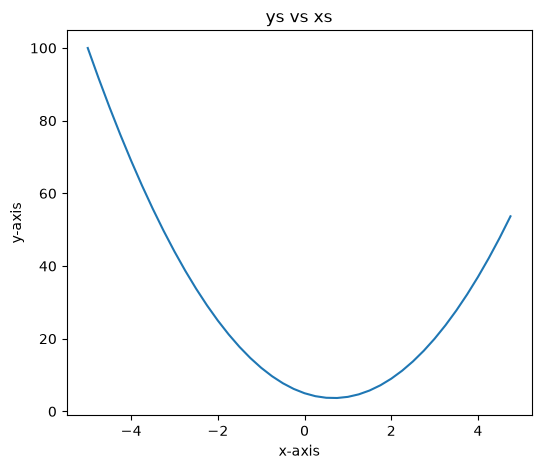

In [276]:
# Visualising the the function using seaborn
plt.figure(figsize=(6, 5))
plt.plot(xs, ys)
plt.title("ys vs xs")
plt.xlabel("x-axis")
plt.ylabel("y-axis")
plt.show()

In [277]:
# Derivative of the function

h = 0.00000001
x = 3.0

print(f(x))
print(f(x+h))
print(f(x + h) - f(x))

# Normalise by h to get the slope
# Derivative from first principle
slope = (f(x + h) - f(x))/h
print(slope)

20.0
20.00000014
1.400000009255109e-07
14.00000009255109


In [278]:
# Derivative of the function

h = 0.00000001
x = 2/3

print(f(x))
print(f(x+h))
print(f(x + h) - f(x))

# Normalise by h to get the slope
# Derivative from first principle
slope = (f(x + h) - f(x))/h
print(slope)

3.666666666666667
3.666666666666667
0.0
0.0


In [279]:
# Let's get more complex
a = 2.0
b = -3.0
c = 10.0
d = a*b + c

print(d)

4.0


In [280]:
# Let's get more complex
h = 0.0001

# Inputs
a = 2.0
b = -3.0
c = 10.0

#### Derivative with respect to `a`

In [281]:
d = a*b + c
d1 = a*b + c

# Find derivative of d w.r.t a
a += h
d2 = a*b + c

# Note: In the ebelow, d2 - d1 is how much the function increases and `h` is the like the difference between `a` before and after increment.

# slope = (d2 - d1)/(a2 - a1) = (d2 - d1)/h

print(f"d1", d1)
print("d2", d2)
print("slope", (d2 - d1)/h)

d1 4.0
d2 3.999699999999999
slope -3.000000000010772


#### Derivative with respect to `b`

In [282]:
# Inputs
a = 2.0
b = -3.0
c = 10.0

d = a*b + c
d1 = a*b + c

# Find derivative of d w.r.t a
b += h # Increase b by a tiny amount `h`
d2 = a*b + c

# Note: In the ebelow, d2 - d1 is how much the function increases and `h` is the like the difference between `b` before and after increment.

# slope = (d2 - d1)/(b2 - b1) = (d2 - d1)/h

print(f"d1", d1)
print("d2", d2)
print("slope", (d2 - d1)/h)

d1 4.0
d2 4.0002
slope 2.0000000000042206


#### Derivative with respect to `b`

In [283]:
# Inputs
a = 2.0
b = -3.0
c = 10.0

d = a*b + c
d1 = a*b + c

# Find derivative of d w.r.t a
c += h # Increase c by a tiny amount `h`
d2 = a*b + c

# Note: In the ebelow, d2 - d1 is how much the function increases and `h` is the like the difference between `c` before and after increment.

# slope = (d2 - d1)/(c2 - c1) = (d2 - d1)/h

print(f"d1", d1)
print("d2", d2)
print("slope", (d2 - d1)/h)

d1 4.0
d2 4.0001
slope 0.9999999999976694


### Moving to Neural Networks

In [284]:
# Build the Value Object

class Value:
    def __init__(self, data):
        self.data = data

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data)
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data)
        return out

In [285]:
a = Value(2.0)
b = Value(-3.0)
c = Value(10)

print(a)
print(b)


print(a.__add__(b))
print(a.__mul__(b))

print(a*b + c)
print(a.__mul__(b).__add__(c))


Value(data=2.0)
Value(data=-3.0)
Value(data=-1.0)
Value(data=-6.0)
Value(data=4.0)
Value(data=4.0)


In [286]:
# Build the Value Object

class Value:
    def __init__(self, data, _children=(), _op=''):
        self.data = data
        self._prev = set(_children)
        self._op = _op

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), '+')
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), '*')
        return out

In [287]:
a = Value(2.0)
b = Value(-3.0)
c = Value(10)
d = a*b + c
print(d)

print(d._prev)
print(d._op)


Value(data=4.0)
{Value(data=-6.0), Value(data=10)}
+


In [288]:
from graphviz import Digraph


def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()

    def build(v):
        if v not in nodes:
            nodes.add(v)

            for child in v._prev:
                edges.add((child, v))
                build(child)

    build(root)
    print(nodes)
    print(edges)
    return nodes, edges


def draw_dot(root):
    dot = Digraph(format="svg", graph_attr={"rankdir": "LR"}) # LR = Left to right 

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))

        # for any value in the graph, create a rectangular (`record`) node for it
        dot.node(name=uid, label="{ data %.4f }" % (n.data, ), shape="record")

        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name=uid + n._op, label = n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # Connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

{Value(data=-3.0), Value(data=2.0), Value(data=10), Value(data=4.0), Value(data=-6.0)}
{(Value(data=10), Value(data=4.0)), (Value(data=-6.0), Value(data=4.0)), (Value(data=-3.0), Value(data=-6.0)), (Value(data=2.0), Value(data=-6.0))}


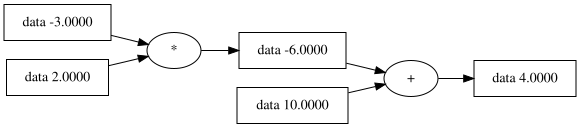

In [289]:
draw_dot(d)

In [290]:
from graphviz import Digraph


def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()

    def build(v):
        if v not in nodes:
            nodes.add(v)

            for child in v._prev:
                edges.add((child, v))
                build(child)

    build(root)
    print(nodes)
    print(edges)
    return nodes, edges


def draw_dot(root):
    dot = Digraph(format="svg", graph_attr={"rankdir": "LR"}) # LR = Left to right 

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))

        # for any value in the graph, create a rectangular (`record`) node for it
        dot.node(name=uid, label="{ %s | data %.4f }" % (n.label, n.data, ), shape="record")

        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name=uid + n._op, label = n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # Connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

In [291]:
# Build the Value Object

class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), '+')
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), '*')
        return out

In [292]:
a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10, label='c')
e = a*b
e.label = "e"
d = e + c
d.label = "d"
f= Value(-2.0, label="f")
L = d * f
L.label = "L"

print(d)
print(L)

print(d._prev)
print(d._op)


Value(data=4.0)
Value(data=-8.0)
{Value(data=-6.0), Value(data=10)}
+


{Value(data=-2.0), Value(data=10), Value(data=4.0), Value(data=2.0), Value(data=-6.0), Value(data=-3.0), Value(data=-8.0)}
{(Value(data=10), Value(data=4.0)), (Value(data=-3.0), Value(data=-6.0)), (Value(data=2.0), Value(data=-6.0)), (Value(data=4.0), Value(data=-8.0)), (Value(data=-2.0), Value(data=-8.0)), (Value(data=-6.0), Value(data=4.0))}


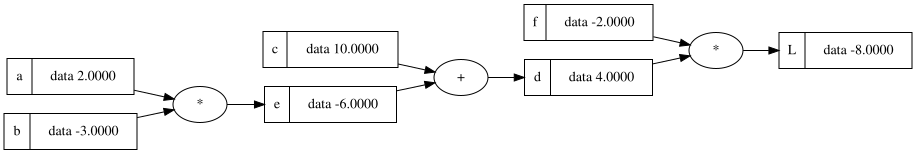

In [293]:
draw_dot(L)

### Backpropagation

In [294]:
# Build the Value Object

class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), '+')
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), '*')
        return out

In [295]:
from graphviz import Digraph


def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()

    def build(v):
        if v not in nodes:
            nodes.add(v)

            for child in v._prev:
                edges.add((child, v))
                build(child)

    build(root)
    print(nodes)
    print(edges)
    return nodes, edges


def draw_dot(root):
    dot = Digraph(format="svg", graph_attr={"rankdir": "LR"}) # LR = Left to right 

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))

        # for any value in the graph, create a rectangular (`record`) node for it
        dot.node(name=uid, label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape="record")

        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name=uid + n._op, label = n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # Connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

In [296]:
a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10, label='c')
e = a*b
e.label = "e"
d = e + c
d.label = "d"
f= Value(-2.0, label="f")
L = d * f
L.label = "L"

print(d)
print(L)

print(d._prev)
print(d._op)


Value(data=4.0)
Value(data=-8.0)
{Value(data=-6.0), Value(data=10)}
+


{Value(data=-6.0), Value(data=-8.0), Value(data=4.0), Value(data=10), Value(data=-3.0), Value(data=2.0), Value(data=-2.0)}
{(Value(data=-3.0), Value(data=-6.0)), (Value(data=-6.0), Value(data=4.0)), (Value(data=2.0), Value(data=-6.0)), (Value(data=10), Value(data=4.0)), (Value(data=-2.0), Value(data=-8.0)), (Value(data=4.0), Value(data=-8.0))}


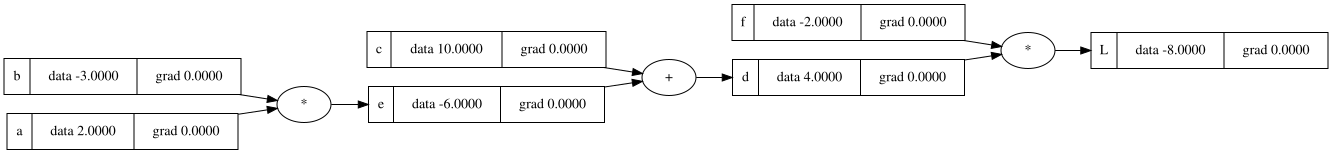

In [297]:
draw_dot(L)

In [298]:
# Build the Value Object

class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), '+')
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), '*')
        return out

1.000000000000334
None
{Value(data=-6.0), Value(data=-8.0), Value(data=4.0), Value(data=10), Value(data=-3.0), Value(data=2.0), Value(data=-2.0)}
{(Value(data=-3.0), Value(data=-6.0)), (Value(data=-6.0), Value(data=4.0)), (Value(data=2.0), Value(data=-6.0)), (Value(data=10), Value(data=4.0)), (Value(data=-2.0), Value(data=-8.0)), (Value(data=4.0), Value(data=-8.0))}


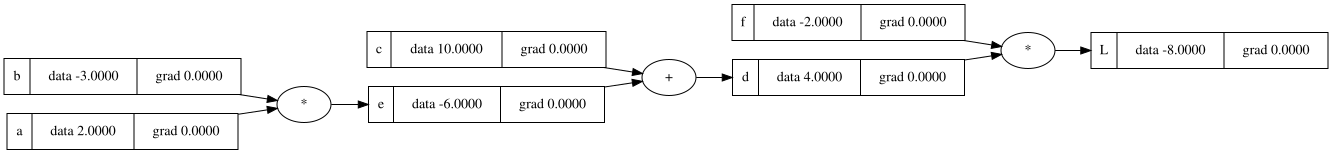

In [299]:
# Derivative of L with respect to L
def lol():
    h = 0.001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10, label='c')
    e = a*b
    e.label = "e"
    d = e + c
    d.label = "d"
    f= Value(-2.0, label="f")
    L = d * f
    L.label = "L"
    L1 = L.data

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10, label='c')
    e = a*b
    e.label = "e"
    d = e + c
    d.label = "d"
    f= Value(-2.0, label="f")
    L = d * f
    L.label = "L"
    L2 = L.data + h

    print((L2 - L1)/h)

print(lol())
draw_dot(L)

In [300]:
# Derivative of L with respect to a
def lol():
    h = 0.0001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10, label='c')
    e = a*b
    e.label = "e"
    d = e + c
    d.label = "d"
    f= Value(-2.0, label="f")
    L = d * f
    L.label = "L"
    L1 = L.data

    a = Value(2.0 + h, label='a')
    b = Value(-3.0, label='b')
    c = Value(10, label='c')
    e = a*b
    e.label = "e"
    d = e + c
    d.label = "d"
    f= Value(-2.0, label="f")
    L = d * f
    L.label = "L"
    L2 = L.data

    print((L2 - L1)/h)

lol()

6.000000000021544


In [301]:
# Derivative of L with respect to L
def lol():
    h = 0.001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10, label='c')
    e = a*b
    e.label = "e"
    d = e + c
    d.label = "d"
    f= Value(-2.0, label="f")
    L = d * f
    L.label = "L"
    L1 = L.data

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10, label='c')
    e = a*b
    e.label = "e"
    d = e + c
    d.label = "d"
    f= Value(-2.0, label="f")
    L = d * f
    L.label = "L"
    L2 = L.data + h

    print((L2 - L1)/h)

lol()

1.000000000000334


In [302]:
# f.grad = 4.0
# d.grad = -2
# draw_dot(L)

{Value(data=-6.0), Value(data=-8.0), Value(data=4.0), Value(data=10), Value(data=-3.0), Value(data=2.0), Value(data=-2.0)}
{(Value(data=-3.0), Value(data=-6.0)), (Value(data=-6.0), Value(data=4.0)), (Value(data=2.0), Value(data=-6.0)), (Value(data=10), Value(data=4.0)), (Value(data=-2.0), Value(data=-8.0)), (Value(data=4.0), Value(data=-8.0))}


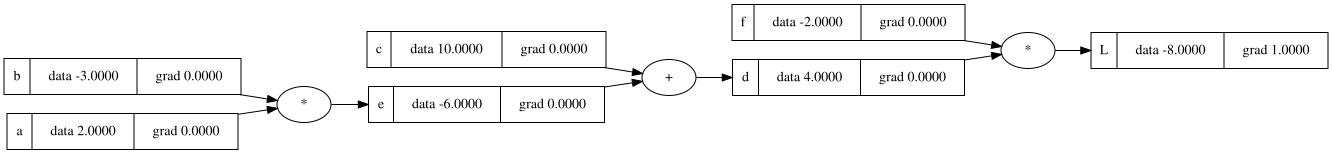

In [303]:
L.grad = 1.0
draw_dot(L)

### Derivative of L with respect to `d` and `f`


In [304]:
# L = d * f # dL/dd = f, dL/df = d

# You can also go back to first principle
# (f(x+h) - f( x))/h
# The above is equivalent to 
# (f(d+h) - f(d))/h = (d*f + h*f - d*f)/h 
# = (h*f)/h
# Therefore dL/dd = f
# and dL/df = d

{Value(data=-6.0), Value(data=-8.0), Value(data=4.0), Value(data=10), Value(data=-3.0), Value(data=2.0), Value(data=-2.0)}
{(Value(data=-3.0), Value(data=-6.0)), (Value(data=-6.0), Value(data=4.0)), (Value(data=2.0), Value(data=-6.0)), (Value(data=10), Value(data=4.0)), (Value(data=-2.0), Value(data=-8.0)), (Value(data=4.0), Value(data=-8.0))}


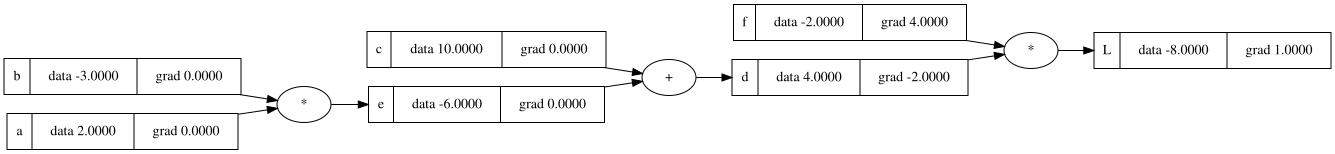

In [305]:
f.grad = 4.0
d.grad = -2.0
draw_dot(L)

In [306]:
# From the graph above, d=4.0 and f=-2.0
# Therefore, d.grad = -2.0 and f.grad=4.0
# Let's verify below

In [307]:
# Derivative of L with respect to f; f.grad = 4.0
# Increment f by h and verify the output  if it's 4.0
def lol():
    h = 0.001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10, label='c')
    e = a*b
    e.label = "e"
    d = e + c
    d.label = "d"
    f= Value(-2.0, label="f")
    L = d * f
    L.label = "L"
    L1 = L.data

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10, label='c')
    e = a*b
    e.label = "e"
    d = e + c
    d.label = "d"
    f = Value(-2.0 + h, label="f")
    L = d * f
    L.label = "L"
    L2 = L.data

    print((L2 - L1)/h)

lol()


3.9999999999995595


In [308]:
# Derivative of L with respect to d; d.grad = -2.0
# Increment d by h and verify the output  if it's -2.0
def lol():
    h = 0.001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10, label='c')
    e = a*b
    e.label = "e"
    d = e + c
    d.label = "d"
    f= Value(-2.0, label="f")
    L = d * f
    L.label = "L"
    L1 = L.data

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10, label='c')
    e = a*b
    e.label = "e"
    d = e + c
    d.label = "d"
    d.data += h
    f = Value(-2.0, label="f")
    L = d * f
    L.label = "L"
    L2 = L.data

    print((L2 - L1)/h)

lol()

-2.000000000000668


In [309]:
# The most important aspect for backpropagation
# This lays a foundation for all training of neural networks
# Let's understand the derivative of L w.r.t. c and the derivative of L w.r.t e.


# dd/ dc = 1.0 and dd/de = 1.0
# dL/dd = -2.0
# dL/dc = (dL/dd) * (dd/dc) = (-2.0 * 1.0) = -2.0
# dL/e = (dL/dd) * (dd/e) = (-2.0 * 1.0) = -2.0

{Value(data=-6.0), Value(data=-8.0), Value(data=4.0), Value(data=10), Value(data=-3.0), Value(data=2.0), Value(data=-2.0)}
{(Value(data=-3.0), Value(data=-6.0)), (Value(data=-6.0), Value(data=4.0)), (Value(data=2.0), Value(data=-6.0)), (Value(data=10), Value(data=4.0)), (Value(data=-2.0), Value(data=-8.0)), (Value(data=4.0), Value(data=-8.0))}


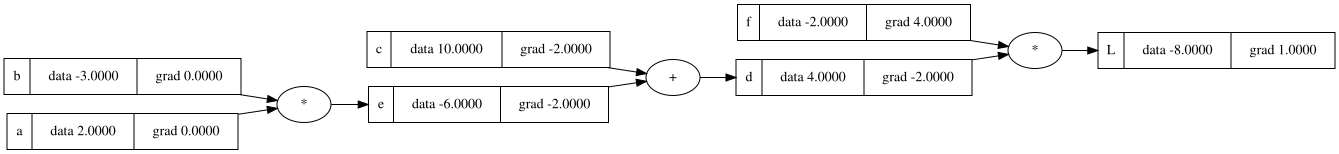

In [310]:
e.grad = -2.0
c.grad = -2.0
draw_dot(L)

In [311]:
# Derivative of L with respect to c; c.grad = -2.0
# Increment c by h and verify the output  if it's -2.0
def lol():
    h = 0.001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10, label='c')
    e = a*b
    e.label = "e"
    d = e + c
    d.label = "d"
    f= Value(-2.0, label="f")
    L = d * f
    L.label = "L"
    L1 = L.data

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10 + h, label='c')
    e = a*b
    e.label = "e"
    d = e + c
    d.label = "d"
    f = Value(-2.0, label="f")
    L = d * f
    L.label = "L"
    L2 = L.data

    print((L2 - L1)/h)

lol()

-1.9999999999988916


In [312]:
# Derivative of L with respect to e; e.grad = -2.0
# Increment e by h and verify the output  if it's -2.0
def lol():
    h = 0.001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10, label='c')
    e = a*b
    e.label = "e"
    d = e + c
    d.label = "d"
    f= Value(-2.0, label="f")
    L = d * f
    L.label = "L"
    L1 = L.data

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10, label='c')
    e = a*b
    e.label = "e"
    e.data += h
    d = e + c
    d.label = "d"
    f = Value(-2.0, label="f")
    L = d * f
    L.label = "L"
    L2 = L.data

    print((L2 - L1)/h)

lol()

-2.000000000000668


### Now finding the derivaives with respect to `a` and `b`
*Compute the derivative based on the expressions*

{Value(data=-6.0), Value(data=-8.0), Value(data=4.0), Value(data=10), Value(data=-3.0), Value(data=2.0), Value(data=-2.0)}
{(Value(data=-3.0), Value(data=-6.0)), (Value(data=-6.0), Value(data=4.0)), (Value(data=2.0), Value(data=-6.0)), (Value(data=10), Value(data=4.0)), (Value(data=-2.0), Value(data=-8.0)), (Value(data=4.0), Value(data=-8.0))}


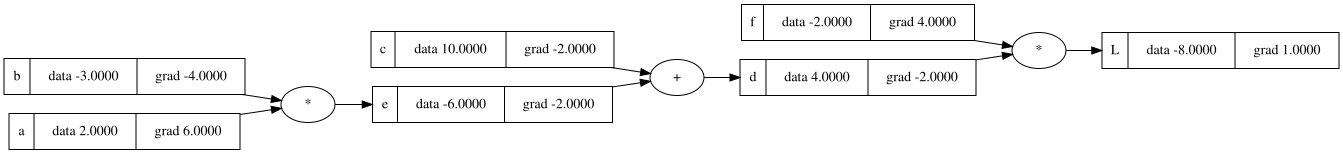

In [313]:
a.grad = 6
b.grad = -4
draw_dot(L)

In [314]:
# Derivative of L with respect to a; a.grad = 6.0
# Increment a by h and verify the output  if it's 6.0
def lol():
    h = 0.001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10, label='c')
    e = a*b
    e.label = "e"
    d = e + c
    d.label = "d"
    f= Value(-2.0, label="f")
    L = d * f
    L.label = "L"
    L1 = L.data

    a = Value(2.0, label='a')
    a.data += h
    b = Value(-3.0, label='b')
    c = Value(10, label='c')
    e = a*b
    e.label = "e"
    d = e + c
    d.label = "d"
    f = Value(-2.0, label="f")
    L = d * f
    L.label = "L"
    L2 = L.data

    print((L2 - L1)/h)

lol()

6.000000000000227


In [315]:
# Derivative of L with respect to b; b.grad = -4.0
# Increment b by h and verify the output  if it's -4.0

def lol():
    h = 0.001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10, label='c')
    e = a*b
    e.label = "e"
    d = e + c
    d.label = "d"
    f= Value(-2.0, label="f")
    L = d * f
    L.label = "L"
    L1 = L.data

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    b.data += h
    c = Value(10, label='c')
    e = a*b
    e.label = "e"
    d = e + c
    d.label = "d"
    f = Value(-2.0, label="f")
    L = d * f
    L.label = "L"
    L2 = L.data

    print((L2 - L1)/h)

lol()

-3.9999999999995595


### Let's update the values of a, b, c and f in order to update L (increase L in the direction of the gradients)

In [316]:
a.data = 0.01 * a.grad
b.data = 0.01 * b.grad
c.data = 0.01 * c.grad
f.data = 0.01 * f.grad

In [317]:
# Re-write the forward pass
e = a * b
d = e + c
L = d * f
print(L.data)

-0.000896


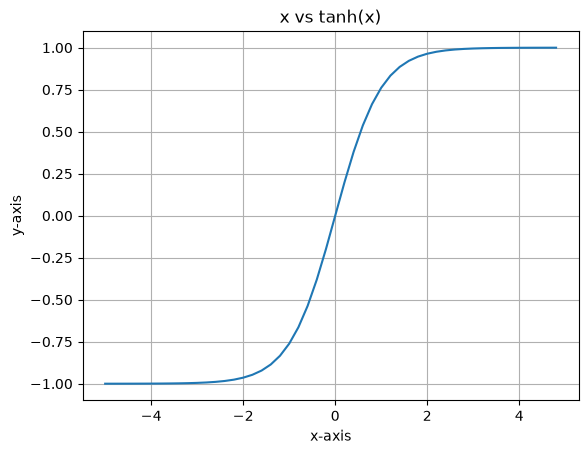

In [318]:
x = np.arange(-5, 5, 0.2)
y = np.tanh(x)
plt.plot(x, y)
plt.title("x vs tanh(x)")
plt.xlabel("x-axis")
plt.ylabel("y-axis")
plt.grid()
plt.show()

In [319]:
import torch
from torch import sigmoid

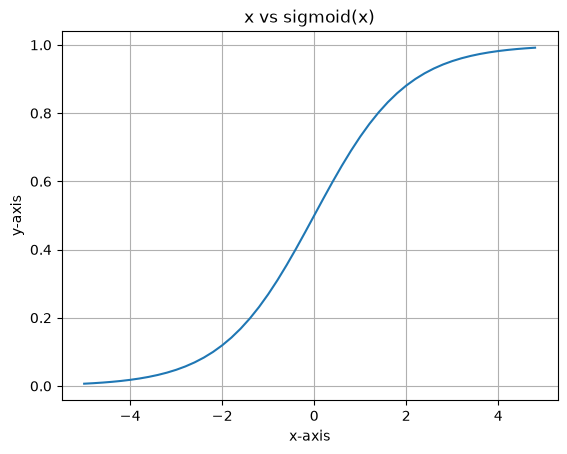

In [320]:
x = torch.arange(-5, 5, 0.2)
y = sigmoid(x)
plt.plot(x, y)
plt.title("x vs sigmoid(x)")
plt.xlabel("x-axis")
plt.ylabel("y-axis")
plt.grid()
plt.show()